# Spatial Join Python with SF data 
Code taken from R and converted into python using Google Gemini in Stanfod playground
Date: 4.16.25


# Spatial Join with HOLC and dependent variables 
Code taken from R and converted into python using Google Gemini in Stanfod playground
Date: 6.7.25


## Intro 
This is where we'll join HOLC polygons with our dependent variables. This has been converted from the joins in R before. We won't need to import bird data, this is just HOLC and the environmental variablse. This will all be done using relational databases


Ultimately we will only have 2 major tables: 
1. iNext response (Done in R, created from raw bird data and HOLC)
2. Environmental Variables 

and we will join based on polygon ID to run RF 

### Dependent Variables 

For Dependent Variables, we have: 

So far we have: 

-eBird data joined with HOLC grade and neighborhood ID
-Avonet 
-Impermeable surface (30 m)
-Canopy Level/complexity (10 m)
-NDVI (3 m) -- Planet data need to import 
-Distance to Highways 
-SF residential zoning shapefile
-pollution data 

Response variable: 
-asym estimates for Richness  (inext)
-then we got to divide it by area to offset it 

In total we should have:
1. 10 different habitat guild dataframes
2. non-native data frame
3. native data frame
4. all species dataframe 


In [2]:
#%pip install pyproj
#%pip install pyogrio

#For this script, use la_env saved on C:/einna/users 
#If it's not working, just making a fresh new virtual environment and install the required packages.


In [3]:
import os
import pyproj

# Get the data directory from pyproj
proj_data_dir = pyproj.datadir.get_data_dir()
os.environ['PROJ_LIB'] = proj_data_dir

In [4]:
#Install and Load required packages in the notebook's environment if not already installed.  This is a one-time step.
#%conda install ipykernel
#%conda install -n sf_env ipykernel --update-deps --force-reinstall
#sf_env is the name of the conda environment
#%conda install duckdb pandas geopandas pyarrow
#%conda install shapely  
#Important for geometric operations



import duckdb
import pandas as pd
import geopandas as gpd
from pathlib import Path
from shapely.geometry import Point
# Import necessary libraries

#%conda install rasterio
#import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.mask import mask


#Connect to DuckDB (in-memory)
con = duckdb.connect()
#con  # Optional: Print the connection object 

#Make sure your DuckDB connection has spatial capabilities
con.sql("INSTALL spatial")
con.sql("LOAD spatial")
con.sql("INSTALL json")
con.sql("LOAD json")

In [5]:

#If you need to update conda you need to check version, run conda isntall conda (verison) and also conda update conda. Then run conda update --all, and verify version again.Kill the terminal and run the activation againf for conda_ch1
# %conda install conda=25.3.1.
# %conda update conda
# %conda init 
# %excute $SHELL
# %conda --version
#close terminal and then run conda activate the env.



In [6]:

#Working Directory Environment Setup

import os

current_directory = os.getcwd()
print(f"Current working directory: {current_directory}")


Current working directory: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code


In [7]:


# Get current working directory
# Create a path relative to the current directory
data_file = Path("../data/dependent_var/redlining/SF_HOLC_cleaned.geojson")
HOLC = gpd.read_file(data_file)

#check it
import folium
HOLC.explore()

#### Hexagons

In [8]:
#Add in hexagons from inext, make sure they're up to date 

# Use Path to construct the file path
path_file = Path("../data/output/sfhex_100_filtered_max_05.01.26_post250.geojson")




# Open the file - remove the square brackets
inext_hex = gpd.read_file(path_file)



inext_hex.explore() 

In [9]:
import geopandas as gpd

inext_hex.crs

<Projected CRS: EPSG:32610>
Name: WGS 84 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 126°W and 120°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - British Columbia (BC); Northwest Territories (NWT); Nunavut; Yukon. United States (USA) - Alaska (AK).
- bounds: (-126.0, 0.0, -120.0, 84.0)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

#### Shapefiles

#### NDVI

In [10]:
#NDVI

from pyproj import Transformer
import rasterio.crs
from pyproj.crs import CRS


with rasterio.Env(OSR_WKT_FORMAT="WKT2_2018"):
    rio_crs = rasterio.crs.CRS.from_epsg(4326)
    proj_crs = CRS.from_user_input(rio_crs)
    
## NDVI
from pathlib import Path
import rasterio

# Use Path to construct the file path
path_file = Path("../data/dependent_var/ndvi_sf_aug2023.tif")

# Open the file - remove the square brackets
ndvi = rasterio.open(path_file)
print(HOLC.crs)
print(ndvi.crs)


EPSG:4326
EPSG:32610


### Polygon


In [11]:

## Socioeconomic ##-----------
nhgis = gpd.read_file(Path('../data/dependent_var/nhgis_SF_join.shp')) #load in shapefile 


## Urban Infrastructure ## -----------
### zoning 
zone_sf = gpd.read_file(Path('../data/dependent_var/SanFrancisco_zoning/SanFrancisco_zoning.shp')) #load in shapefile 



### pollution
pollution_sf = pd.read_csv(Path("../data/dependent_var/cesar_pollutiondata_10_29_24.csv")) #read csv 

#we'll have to join via columns in the next steps



In [12]:

#Data Preparation and Transformation

#Add together rasters and shapefiles for HOLC ID neighborhoods 

# Project data
#shapefiles 
crs = "EPSG:32610" # UTM Zone 10N, for San Francisco
holc_prj = HOLC.to_crs(crs)
nhgis_prj = nhgis.to_crs(crs)
zone_sf_prj = zone_sf.to_crs(crs)
hex_prj = inext_hex.to_crs(crs) 
nhgis_prj.explore()





In [13]:
# ============================================================
# FIX: DEDUPLICATE HEX_PRJ BEFORE JOIN
# ============================================================

def prepare_unique_hexagons(hex_prj):
    """
    Remove duplicates from hexagon data
    """
    print("=" * 60)
    print("DEDUPLICATING HEXAGON DATA")
    print("=" * 60)
    print(f"Original rows: {len(hex_prj)}")
    print(f"Unique hex_ids: {hex_prj['hex_id'].nunique()}")
    
    # Check what columns exist
    print(f"\nColumns: {list(hex_prj.columns)}")
    

    # Option 1: If duplicates are true duplicates (all columns identical)
    # Just keep first occurrence
    hex_prj = hex_prj.drop(columns=['scientific_name', 'max_observations'], errors='ignore')
    hex_unique = hex_prj.drop_duplicates().copy()
    
    print(f"\nAfter deduplication: {len(hex_unique)} rows")
    print(f"Unique hex_ids: {hex_unique['hex_id'].nunique()}")
    
    return hex_unique

# Deduplicate BEFORE running demographic calculation
hex_prj_clean = prepare_unique_hexagons(hex_prj)

# NOW run the demographic function with clean data



DEDUPLICATING HEXAGON DATA
Original rows: 2423
Unique hex_ids: 253

Columns: ['scientific_name', 'hex_id', 'max_observations', 'grade', 'geometry']

After deduplication: 253 rows
Unique hex_ids: 253


#### Raster

In [14]:
#%conda install rioxarray

import rioxarray as rxr
#Takes about 2 minutes
#Reproject the data using the crs from the roads layer
#upload raster data as rasterio objects 
### impermable surfaces (we're just going to grab the one from LA for now since SF is messed up and too low resolution, it also includes SF Bay Area)
imperm = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_LA_redlining/data/dependent_var/ca_2021_ccap_v2_hires_impervious_20240108.tif'),
                              masked=True).squeeze()


In [15]:

highway = rxr.open_rasterio(Path('../data/dependent_var/euc_highway_sf_3m.tif'),
                            masked=True).squeeze()

canopy = rxr.open_rasterio(Path('../data/dependent_var/fhd_final.tif'),
                           masked=True).squeeze()

ndvi = rxr.open_rasterio(Path('../data/dependent_var/ndvi_sf_aug2023.tif'), 
                         masked=True).squeeze()



In [16]:
# First, we neeed to cut down impervious surface
print("Imperm CRS:", imperm.rio.crs)
print("HOLC CRS:", HOLC.crs)

# Reproject HOLC to match the raster CRS
holc_reproj = HOLC.to_crs(imperm.rio.crs)

# Now get bounds and clip
bbox = holc_reproj.total_bounds
print("Bbox:", bbox)

# Check if bounds overlap with raster bounds
print("Raster bounds:", imperm.rio.bounds())

# Clip the raster
imperm_clipped = imperm.rio.clip_box(
    minx=bbox[0],
    miny=bbox[1],
    maxx=bbox[2],
    maxy=bbox[3]
)



Imperm CRS: EPSG:5070
HOLC CRS: EPSG:4326
Bbox: [-2283945.5650474   1948293.47081641 -2272125.85004564  1959839.12903064]
Raster bounds: (-2356246.37438353, 1258586.50905489, -1823800.37438353, 2453525.50905489)


# Canopy

We accidentally didn't use the correct EPGS for SF, according to 3DEP report: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/metadata/CA_SanFrancisco_B23/CA_SanFrancisco_1_B23/reports/USGS_CA_SanFrancisco_1_B23_Summary_Report.pdf they used 7131

In [17]:
# Set the correct CRS for canopy
canopy_corrected = canopy.rio.write_crs('EPSG:7131', inplace=False)

# Now reproject to match hexagons
canopy_prj = canopy_corrected.rio.reproject(hex_prj_clean.crs)

# Verify it works
print("Corrected canopy bounds:", canopy_prj.rio.bounds())
print("Hexagon bounds:", hex_prj_clean.total_bounds)

from shapely.geometry import box
canopy_bbox = box(*canopy_prj.rio.bounds())
hex_bbox = box(*hex_prj_clean.total_bounds)
print("Overlaps?", canopy_bbox.intersects(hex_bbox))
canopy_prj.rio.crs

Corrected canopy bounds: (542577.4557813618, 4172310.0431112694, 559359.1589995513, 4187982.16266421)
Hexagon bounds: [ 543345.9912916  4173753.76598479  555845.9912916  4184434.74596479]
Overlaps? True


CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]')

In [18]:
#reproject all rasters to same crs
#takes about 4 minutes
ndvi_prj = ndvi.rio.reproject(crs)

highway_prj = highway.rio.reproject(crs)

imperm_prj = imperm_clipped.rio.reproject(crs)



# Export Raster images


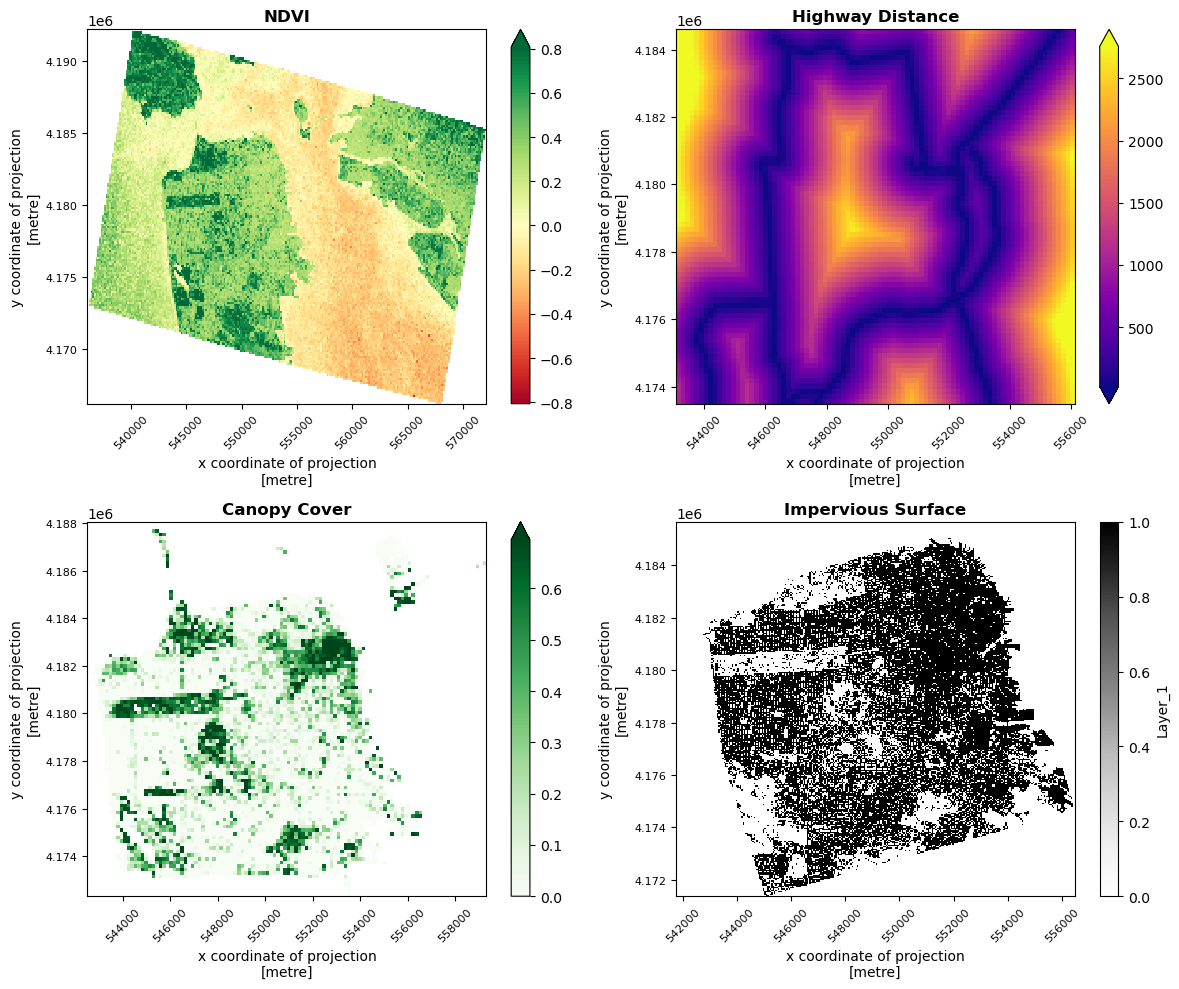

In [19]:
downsample = 50

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# NDVI
ndvi_prj[::downsample, ::downsample].plot(ax=axes[0, 0], cmap='RdYlGn', robust=True)
axes[0, 0].set_title('NDVI', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0, 0].tick_params(axis='y', labelsize=8)

# Highway
highway_prj[::downsample, ::downsample].plot(ax=axes[0, 1], cmap='plasma', robust=True)
axes[0, 1].set_title('Highway Distance', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45, labelsize=8)
axes[0, 1].tick_params(axis='y', labelsize=8)

# Canopy
canopy_prj[::downsample, ::downsample].plot(ax=axes[1, 0], cmap='Greens', robust=True)
axes[1, 0].set_title('Canopy Cover', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45, labelsize=8)
axes[1, 0].tick_params(axis='y', labelsize=8)

# Impervious
imperm_prj[::downsample, ::downsample].plot(ax=axes[1, 1], cmap='Greys', robust=True)
axes[1, 1].set_title('Impervious Surface', fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1, 1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig('../results_images/raster_preview_4.16.26.png', dpi=300, bbox_inches='tight')
plt.show()



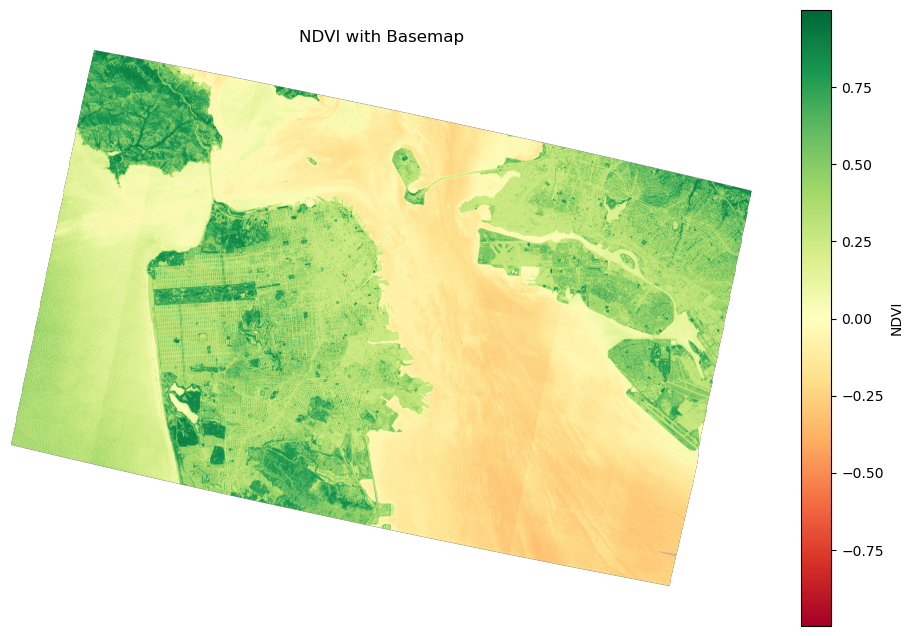

In [20]:
#%pip install contextily
import contextily as ctx

# Get the bounds of the raster
left, bottom, right, top = ndvi_prj.rio.bounds()

fig, ax = plt.subplots(figsize=(12, 8))

# Plot a downsampled version of the raster
im = ax.imshow(ndvi_prj, extent=[left, right, bottom, top], 
               cmap='RdYlGn')

# Add a basemap
#ctx.add_basemap(ax, crs=ndvi.rio.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

plt.colorbar(im, label='NDVI')
plt.title('NDVI with Basemap')
plt.axis('off')
plt.show()

In [21]:
""" 
import folium
from folium import plugins
from folium import raster_layers

#So here are all layers 
#vectors

'''
ndvi_prj
highway_prj
canopy_prj
imperm_prj      
holc_prj 
nhgis_prj
zone_sf_prj
pollution_sf

'''


import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import io

# Create a base map centered on San Francisco
m = folium.Map(location=[37.7749, -122.4194], zoom_start=12)


# Add hex layer
hex_prj_clean.explore(
    m=m, 
    legend=True, 
    tooltip=['hex_id'],
    name='Hexagons'  # Layer name for control
)

# Add impervious surface layer
# Add RASTER layer (impervious surface)
if hasattr(imperm_prj, 'rio'):  # If it's a rioxarray
    # Get bounds
    bounds = [[imperm_prj.rio.bounds()[1], imperm_prj.rio.bounds()[0]], 
              [imperm_prj.rio.bounds()[3], imperm_prj.rio.bounds()[2]]]
    
    # Normalize data for display
    data = imperm_prj.values
    data_norm = (data - np.nanmin(data)) / (np.nanmax(data) - np.nanmin(data))
    
    # Create colored image using colormap
    cmap = plt.cm.Reds
    colored_data = cmap(data_norm)
    
    # Add to map
    folium.raster_layers.ImageOverlay(
        image=colored_data,
        bounds=bounds,
        opacity=0.6,
        name='Impervious Surface'
    ).add_to(m)



 """

" \nimport folium\nfrom folium import plugins\nfrom folium import raster_layers\n\n#So here are all layers \n#vectors\n\n'''\nndvi_prj\nhighway_prj\ncanopy_prj\nimperm_prj      \nholc_prj \nnhgis_prj\nzone_sf_prj\npollution_sf\n\n'''\n\n\nimport matplotlib.pyplot as plt\nfrom matplotlib.colors import LinearSegmentedColormap\nimport io\n\n# Create a base map centered on San Francisco\nm = folium.Map(location=[37.7749, -122.4194], zoom_start=12)\n\n\n# Add hex layer\nhex_prj_clean.explore(\n    m=m, \n    legend=True, \n    tooltip=['hex_id'],\n    name='Hexagons'  # Layer name for control\n)\n\n# Add impervious surface layer\n# Add RASTER layer (impervious surface)\nif hasattr(imperm_prj, 'rio'):  # If it's a rioxarray\n    # Get bounds\n    bounds = [[imperm_prj.rio.bounds()[1], imperm_prj.rio.bounds()[0]], \n              [imperm_prj.rio.bounds()[3], imperm_prj.rio.bounds()[2]]]\n\n    # Normalize data for display\n    data = imperm_prj.values\n    data_norm = (data - np.nanmin(data))

In [22]:
""" if hasattr(highway_prj, 'rio'):  # If it's a rioxarray
    # Get bounds
    bounds = [[highway_prj.rio.bounds()[1], highway_prj.rio.bounds()[0]], 
              [highway_prj.rio.bounds()[3], highway_prj.rio.bounds()[2]]]
    
    # Normalize data for display
    data = highway_prj.values
    data_norm = (data - np.nanmin(data)) / (np.nanmax(data) - np.nanmin(data))
    
    # Create colored image using colormap
    cmap = plt.cm.Reds
    colored_data = cmap(data_norm)
    
    # Add to map
    folium.raster_layers.ImageOverlay(
        image=colored_data,
        bounds=bounds,
        opacity=0.6,
        name='Highways'
    ).add_to(m)
 """

" if hasattr(highway_prj, 'rio'):  # If it's a rioxarray\n    # Get bounds\n    bounds = [[highway_prj.rio.bounds()[1], highway_prj.rio.bounds()[0]], \n              [highway_prj.rio.bounds()[3], highway_prj.rio.bounds()[2]]]\n\n    # Normalize data for display\n    data = highway_prj.values\n    data_norm = (data - np.nanmin(data)) / (np.nanmax(data) - np.nanmin(data))\n\n    # Create colored image using colormap\n    cmap = plt.cm.Reds\n    colored_data = cmap(data_norm)\n\n    # Add to map\n    folium.raster_layers.ImageOverlay(\n        image=colored_data,\n        bounds=bounds,\n        opacity=0.6,\n        name='Highways'\n    ).add_to(m)\n "

In [23]:
""" import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

# Plot raster (impervious surface)
imperm_prj.plot(ax=ax, cmap='Greys', alpha=0.7, add_colorbar=True)

# Plot vector (hex grid) on top
hex_prj_clean.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1.5)

plt.title('Overlay: Impervious Surface (grey) and Hex Grid (red outline)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.show() """

" import matplotlib.pyplot as plt\n\nfig, ax = plt.subplots(figsize=(12, 10))\n\n# Plot raster (impervious surface)\nimperm_prj.plot(ax=ax, cmap='Greys', alpha=0.7, add_colorbar=True)\n\n# Plot vector (hex grid) on top\nhex_prj_clean.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1.5)\n\nplt.title('Overlay: Impervious Surface (grey) and Hex Grid (red outline)')\nplt.xlabel('X coordinate')\nplt.ylabel('Y coordinate')\nplt.show() "

In [24]:
""" # Check if all rasters have the same extent
print("Highway bounds:", highway_prj.rio.bounds())
print("NDVI bounds:", ndvi_prj.rio.bounds())
print("Hexagon bounds:", hex_prj_clean.total_bounds)

# Visualize the mismatch
fig, ax = plt.subplots(figsize=(10, 10))
highway_prj.plot(ax=ax, alpha=0.5)
hex_prj_clean.boundary.plot(ax=ax, color='red', linewidth=0.5)
plt.title("Highway Distance Raster vs Hexagons")
plt.show() """

' # Check if all rasters have the same extent\nprint("Highway bounds:", highway_prj.rio.bounds())\nprint("NDVI bounds:", ndvi_prj.rio.bounds())\nprint("Hexagon bounds:", hex_prj_clean.total_bounds)\n\n# Visualize the mismatch\nfig, ax = plt.subplots(figsize=(10, 10))\nhighway_prj.plot(ax=ax, alpha=0.5)\nhex_prj_clean.boundary.plot(ax=ax, color=\'red\', linewidth=0.5)\nplt.title("Highway Distance Raster vs Hexagons")\nplt.show() '

# Raster Stats

In [25]:
import numpy as np
#%conda install rasterstats
#%conda install xarray

import rasterstats
import xarray as xr
from rasterstats import zonal_stats


# 1. RESET INDEX FIRST (crucial step!)
hex_prj_clean = hex_prj_clean.reset_index(drop=True)

# NDVI stats
ndvi_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    ndvi_prj.values,
    affine=ndvi_prj.rio.transform(),  # Use NDVI's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Highway stats
highway_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    highway_prj.values,
    affine=highway_prj.rio.transform(),  # Use Highway's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Impervious stats
imperm_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    imperm_prj.values,
    affine=imperm_prj.rio.transform(),  # Use Impervious's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Canopy stats
canopy_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    canopy_prj.values,
    affine=canopy_prj.rio.transform(),  # Use Canopy's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Convert to DataFrames with suffixes
ndvi_df = pd.DataFrame(ndvi_stats).add_suffix('_ndvi')
highway_df = pd.DataFrame(highway_stats).add_suffix('_highway')
imperm_df = pd.DataFrame(imperm_stats).add_suffix('_imperm')
canopy_df = pd.DataFrame(canopy_stats).add_suffix('_canopy')

# Join all
result_gdf = hex_prj_clean.join([ndvi_df, highway_df, imperm_df, canopy_df])

print(result_gdf.head())
print(f"NA values after fixing: {result_gdf['mean_ndvi'].isna().sum()}")


# 5. Verify
print(f"Total hexagons: {len(result_gdf)}")
print(f"\nNA counts per variable:")
print(result_gdf[['mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy']].isna().sum())
print(f"\nSample data:")
print(result_gdf[['mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy']].head(10))


   hex_id grade                                           geometry  min_ndvi  \
0   810_B     B  POLYGON ((545495.991 4177564.278, 545445.991 4...  0.225631   
1  2441_C     C  POLYGON ((549195.991 4179642.739, 549145.991 4...  0.246686   
2  1035_B     B  POLYGON ((546145.991 4180768.572, 546095.991 4...  0.215332   
3  2125_C     C  POLYGON ((548545.991 4179902.546, 548495.991 4...  0.235287   
4  3146_C     C  POLYGON ((550395.991 4178083.893, 550345.991 4...  0.208318   

   max_ndvi  mean_ndvi  count_ndvi  std_ndvi  median_ndvi  majority_ndvi  ...  \
0  0.608597   0.354324        1026  0.070134     0.341767       0.334402  ...   
1  0.804569   0.553618        1027  0.143608     0.544770       0.475168  ...   
2  0.715554   0.426761        1050  0.115047     0.386729       0.370332  ...   
3  0.760608   0.472409        1048  0.139354     0.425728       0.320298  ...   
4  0.768230   0.449064        1029  0.132818     0.428537       0.208318  ...   

   std_imperm  median_imperm  ma

Canopy NoData value: nan
Canopy has NaN: 15307696
Canopy value range: 0.0 to 1.3112495


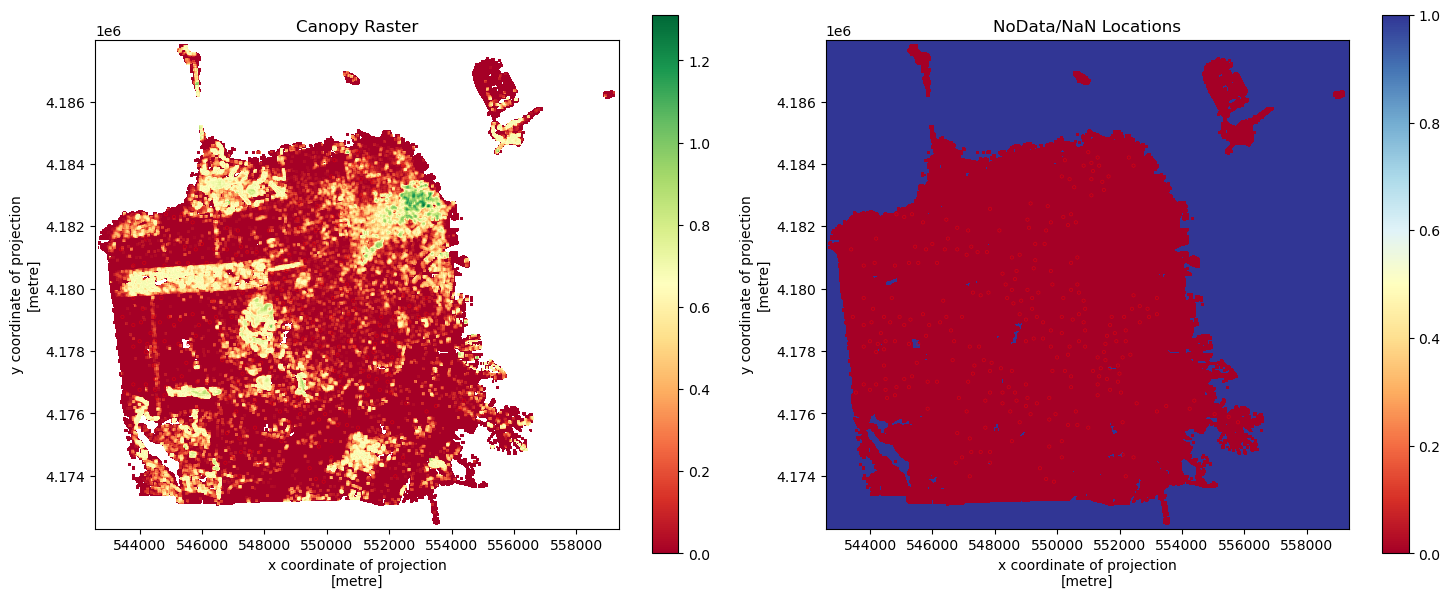

In [26]:
# Check NoData handling
print("Canopy NoData value:", canopy_prj.rio.nodata)
print("Canopy has NaN:", canopy_prj.isnull().sum().values)
print("Canopy value range:", canopy_prj.min().values, "to", canopy_prj.max().values)

# Visualize NoData locations
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot raster
canopy_prj.plot(ax=ax[0], cmap='RdYlGn')
ax[0].set_title('Canopy Raster')

# Plot NaN mask
canopy_prj.isnull().plot(ax=ax[1], cmap='RdYlBu')
ax[1].set_title('NoData/NaN Locations')

# Overlay hexagons
hex_prj_clean.boundary.plot(ax=ax[0], color='red', linewidth=0.5, alpha=0.5)
hex_prj_clean.boundary.plot(ax=ax[1], color='red', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

In [27]:
""" # The coordinate range (42180, 18123, 58878, 33702) is suspicious
# These could be:
# - A different UTM zone
# - Feet instead of meters
# - State Plane coordinates
# - Wrong hemisphere

from shapely.geometry import box

# Try to guess the correct CRS by checking what makes sense
from pyproj import Transformer

# Check if these are actually in a different UTM zone
# (Your hexagons are in UTM Zone 10N, maybe canopy is in a different zone?)

# Let's see where these coordinates would be in common CRS systems
possible_crs = ['EPSG:6340', 'EPSG:7131', 'EPSG:2229', 'EPSG:26910']
target_crs = 'EPSG:32610'  # WGS84 for visualization
for crs_code in possible_crs:
    try:
        # Set canopy to this CRS
        canopy_test = canopy.rio.write_crs(crs_code, inplace=False)
        # Reproject to target
        canopy_reproj = canopy_test.rio.reproject(target_crs)
        bounds = canopy_reproj.rio.bounds()
        
        # Check if bounds are reasonable
        bbox = box(*bounds)
        hex_bbox = box(*hex_prj_clean.total_bounds)
        overlaps = bbox.intersects(hex_bbox)
        
        print(f"\n{crs_code}: {bounds}")
        print(f"  Overlaps with hexagons: {overlaps}")
    except:
        print(f"\n{crs_code}: Failed") """

' # The coordinate range (42180, 18123, 58878, 33702) is suspicious\n# These could be:\n# - A different UTM zone\n# - Feet instead of meters\n# - State Plane coordinates\n# - Wrong hemisphere\n\nfrom shapely.geometry import box\n\n# Try to guess the correct CRS by checking what makes sense\nfrom pyproj import Transformer\n\n# Check if these are actually in a different UTM zone\n# (Your hexagons are in UTM Zone 10N, maybe canopy is in a different zone?)\n\n# Let\'s see where these coordinates would be in common CRS systems\npossible_crs = [\'EPSG:6340\', \'EPSG:7131\', \'EPSG:2229\', \'EPSG:26910\']\ntarget_crs = \'EPSG:32610\'  # WGS84 for visualization\nfor crs_code in possible_crs:\n    try:\n        # Set canopy to this CRS\n        canopy_test = canopy.rio.write_crs(crs_code, inplace=False)\n        # Reproject to target\n        canopy_reproj = canopy_test.rio.reproject(target_crs)\n        bounds = canopy_reproj.rio.bounds()\n\n        # Check if bounds are reasonable\n        bb

In [28]:
""" # Step 1: Rename columns
nhgis_prj1 = nhgis_prj[['AMP3E001', 'AMP3E003', 'AMP3E004', 'AMP3E005', 'AMP3E006', 
                       'AMP3E007', 'AMP3E008', 'AMR8E001', 'AMP3E012', 'geometry']]

nhgis_prj1 = nhgis_prj1.rename(columns={
    'AMP3E001': 'TOTPOP',
    'AMP3E003': 'NH_WHITE',
    'AMP3E004': 'NH_BLACK',
    'AMP3E005': 'NH_AMIN',
    'AMP3E006': 'NH_ASIAN',
    'AMP3E007': 'NH_NHPI',
    'AMP3E008': 'NH_OTHER',
    'AMR8E001': 'MED_INCOME',
    'AMP3E012': 'LATINE'
})

# Step 2: Spatial join to get overlaps
nhgis_join_raw = gpd.sjoin(hex_prj_clean, nhgis_prj1, how='inner', predicate='intersects')

# Step 3: Calculate intersection areas for weighting
# Get actual intersection geometries and their areas
overlay = gpd.overlay(hex_prj_clean, nhgis_prj1, how='intersection')
overlay['intersection_area'] = overlay.geometry.area

# Step 4: Calculate population-weighted demographics at hexagon level
pop_columns = ['NH_WHITE', 'NH_BLACK', 'NH_AMIN', 'NH_ASIAN', 'NH_NHPI', 'NH_OTHER', 'LATINE']

# Group by hex_id and calculate weighted sums
nhgis_aggregated = overlay.groupby('hex_id').apply(
    lambda x: pd.Series({
        # Total population (sum across all intersecting census blocks)
        'TOTPOP': x['TOTPOP'].sum(),
        
        # For each demographic: sum the counts (not percentages yet)
        'NH_WHITE': x['NH_WHITE'].sum(),
        'NH_BLACK': x['NH_BLACK'].sum(),
        'NH_AMIN': x['NH_AMIN'].sum(),
        'NH_ASIAN': x['NH_ASIAN'].sum(),
        'NH_NHPI': x['NH_NHPI'].sum(),
        'NH_OTHER': x['NH_OTHER'].sum(),
        'LATINE': x['LATINE'].sum(),
        
        # For median income: population-weighted average
        'MED_INCOME': (x['MED_INCOME'] * x['TOTPOP']).sum() / x['TOTPOP'].sum() if x['TOTPOP'].sum() > 0 else 0,
        
        # Keep hex attributes
        'holc_grade': x['holc_grade'].iloc[0] if 'holc_grade' in x.columns else None,
        'geometry': x['geometry'].iloc[0]  # This gets the hex geometry
    })
).reset_index()

# Step 5: Calculate percentages based on aggregated populations
nhgis_aggregated['WHITE_PER'] = (nhgis_aggregated['NH_WHITE'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['BLACK_PER'] = (nhgis_aggregated['NH_BLACK'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['AMIN_PER'] = (nhgis_aggregated['NH_AMIN'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['ASIAN_PER'] = (nhgis_aggregated['NH_ASIAN'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['NHPI_PER'] = (nhgis_aggregated['NH_NHPI'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['OTHER_PER'] = (nhgis_aggregated['NH_OTHER'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)
nhgis_aggregated['LATINE_PER'] = (nhgis_aggregated['LATINE'] / nhgis_aggregated['TOTPOP'] * 100).fillna(0)

# Step 6: Use aggregated data as nhgis_join
nhgis_join = nhgis_aggregated

# Verify results
print(f"Original hexagons: {len(hex_prj_clean)}")
print(f"Hexagons with demographics: {len(nhgis_join)}")
print(f"\nSample data:")
print(nhgis_join[['hex_id', 'TOTPOP', 'WHITE_PER', 'BLACK_PER', 'ASIAN_PER', 'LATINE_PER']].head())

# Check for any hexagons that intersected multiple census blocks
print(f"\nHexagons that intersected multiple census blocks:")
multi_block = nhgis_join_raw.groupby('hex_id').size()
print(f"Hexagons with multiple blocks: {(multi_block > 1).sum()}") """

' # Step 1: Rename columns\nnhgis_prj1 = nhgis_prj[[\'AMP3E001\', \'AMP3E003\', \'AMP3E004\', \'AMP3E005\', \'AMP3E006\', \n                       \'AMP3E007\', \'AMP3E008\', \'AMR8E001\', \'AMP3E012\', \'geometry\']]\n\nnhgis_prj1 = nhgis_prj1.rename(columns={\n    \'AMP3E001\': \'TOTPOP\',\n    \'AMP3E003\': \'NH_WHITE\',\n    \'AMP3E004\': \'NH_BLACK\',\n    \'AMP3E005\': \'NH_AMIN\',\n    \'AMP3E006\': \'NH_ASIAN\',\n    \'AMP3E007\': \'NH_NHPI\',\n    \'AMP3E008\': \'NH_OTHER\',\n    \'AMR8E001\': \'MED_INCOME\',\n    \'AMP3E012\': \'LATINE\'\n})\n\n# Step 2: Spatial join to get overlaps\nnhgis_join_raw = gpd.sjoin(hex_prj_clean, nhgis_prj1, how=\'inner\', predicate=\'intersects\')\n\n# Step 3: Calculate intersection areas for weighting\n# Get actual intersection geometries and their areas\noverlay = gpd.overlay(hex_prj_clean, nhgis_prj1, how=\'intersection\')\noverlay[\'intersection_area\'] = overlay.geometry.area\n\n# Step 4: Calculate population-weighted demographics at hexagon

# NHGIS Percentages

In [29]:

nhgis_prj = nhgis_prj[['AMP3E001', 'AMP3E003', 'AMP3E004', 'AMP3E005', 'AMP3E006', 
                       'AMP3E007', 'AMP3E008', 'AMR8E001', 'AMP3E012', 'geometry']]
                       

nhgis_prj = nhgis_prj.rename(columns={
    'AMP3E001': 'TOTPOP',
    'AMP3E003': 'NH_WHITE',
    'AMP3E004': 'NH_BLACK',
    'AMP3E005': 'NH_AMIN',
    'AMP3E006': 'NH_ASIAN',
    'AMP3E007': 'NH_NHPI',
    'AMP3E008': 'NH_OTHER',
    'AMR8E001': 'MED_INCOME',
    'AMP3E012': 'LATINE'
})



#nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj1, how='inner', predicate='intersects') #check if it works using .head()


"""
# Create percentage columns for each demographic group
nhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']
nhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']
nhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']
nhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']
nhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']
nhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']
nhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']

# Handle any potential division by zero errors (if there are census tracts with zero population)
percentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']
nhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)

# You might want to multiply by 100 to get actual percentages
nhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100

# Check the new columns
print(nhgis_join[['TOTPOP'] + percentage_columns].head())

"""

"\n# Create percentage columns for each demographic group\nnhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']\nnhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']\nnhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']\nnhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']\nnhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']\nnhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']\nnhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']\n\n# Handle any potential division by zero errors (if there are census tracts with zero population)\npercentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)\n\n# You might want to multiply by 100 to get actual percentages\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100\n\n# Check t

In [30]:
#add zoning and use area to see the % of the polygon designated as single/multi 
#also add in pop/dense 

#we need to calculate zone area 

hex_prj = hex_prj_clean
# Calculate area in square meters (if using a projected CRS)
zone_sf_prj['area_m2'] = zone_sf_prj.geometry.area
hex_prj['area_m2'] = hex_prj.geometry.area

zone_join = gpd.sjoin(hex_prj, zone_sf_prj, how='inner', predicate='intersects') #check if it works using .head()

#now calc percentages
# First, let's get the proper intersection geometries (not just the overlapping polygons)
# This creates actual intersection geometries
overlay = gpd.overlay(hex_prj, zone_sf_prj, how='intersection')

# Calculate the area of each intersection
overlay['intersection_area'] = overlay.geometry.area

# Group by HOLC polygon ID and zoning type to sum up areas
# Assuming 'holc_id' is your HOLC polygon identifier and 'zone_type' is your zoning category
# Replace these with your actual column names
grouped = overlay.groupby(['hex_id', 'Zoning']).agg({'intersection_area': 'sum'}).reset_index()

# Merge with original HOLC data to get the total area of each HOLC polygon
# Assuming 'holc_id' is your HOLC polygon identifier
merged = grouped.merge(hex_prj[['hex_id', 'area_m2']], on='hex_id')

# Calculate percentage
merged['percentage'] = (merged['intersection_area'] / merged['area_m2']) * 100

# View the results
print(merged[['hex_id', 'Zoning', 'percentage']])

# If you want to pivot this into a more readable format with HOLC grades as rows and zoning types as columns:
#pivot_table = merged.pivot(index='hex_id', columns='Zoning', values='percentage')
# Fix for the NameError
# First create the pivot table
aggregated = merged.groupby(['hex_id', 'Zoning'])['percentage'].agg('sum').reset_index()
pivot_table = aggregated.pivot(index='hex_id', columns='Zoning', values='percentage')
pivot_table = pivot_table.fillna(0)


print(pivot_table.fillna(0))  # Fill NaN with 0 for areas with no intersection


     hex_id  Zoning  percentage
0    1031_B     1.0    8.973801
1    1035_B     2.0   80.088033
2    1069_B     1.0   59.556786
3    1106_C     2.0   73.215586
4    1123_B     2.0   83.348855
..      ...     ...         ...
261   931_B     2.0   78.797976
262   934_A     1.0   62.124948
263   936_B     1.0   26.864070
264   949_B     1.0   62.907268
265   990_B     2.0   51.346051

[266 rows x 3 columns]
Zoning  0.0        1.0        2.0
hex_id                           
1031_B  0.0   8.973801   0.000000
1035_B  0.0   0.000000  80.088033
1069_B  0.0  59.556786   0.000000
1106_C  0.0   0.000000  73.215586
1123_B  0.0   0.000000  83.348855
...     ...        ...        ...
931_B   0.0   0.000000  78.797976
934_A   0.0  62.124948   0.000000
936_B   0.0  26.864070   0.000000
949_B   0.0  62.907268   0.000000
990_B   0.0   0.000000  51.346051

[244 rows x 3 columns]


In [31]:

# ============================================================
# COMPLETE WORKFLOW WITH POPULATION DENSITY
# ============================================================


def calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj):
    """
    Complete workflow: demographics + population density
    """
    # 1. CLEAN MEDIAN INCOME DATA FIRST
    print("=" * 60)
    print("CLEANING MEDIAN INCOME DATA")
    print("=" * 60)
    
    # Check for negative/invalid values
    invalid_income = nhgis_prj[nhgis_prj['MED_INCOME'] < 0]
    print(f"Block groups with invalid income: {len(invalid_income)}/{len(nhgis_prj)}")
    
    if len(invalid_income) > 0:
        print(f"Invalid income values found: {invalid_income['MED_INCOME'].unique()}")
    
    # Replace invalid values with NaN
    nhgis_prj['MED_INCOME'] = nhgis_prj['MED_INCOME'].apply(
        lambda x: np.nan if x < 0 else x
    )
    
    # 1. Calculate percentages on block groups
    demographic_cols = ['NH_WHITE', 'NH_BLACK', 'NH_AMIN', 'NH_ASIAN', 
                       'NH_NHPI', 'NH_OTHER', 'LATINE']
    
    for col in demographic_cols:
        pct_col = col + '_PER'
        nhgis_prj[pct_col] = np.where(
            nhgis_prj['TOTPOP'] > 0,
            (nhgis_prj[col] / nhgis_prj['TOTPOP']) * 100,
            0
        )
    
    # POC percentage
    nhgis_prj['POC_PER'] = np.where(
        nhgis_prj['TOTPOP'] > 0,
        ((nhgis_prj['NH_BLACK'] + nhgis_prj['NH_AMIN'] + nhgis_prj['NH_ASIAN'] + 
          nhgis_prj['NH_NHPI'] + nhgis_prj['NH_OTHER'] + nhgis_prj['LATINE']) / 
         nhgis_prj['TOTPOP']) * 100,
        0
    )
    
    # Block group area and density
    nhgis_prj['bg_area_sqkm'] = nhgis_prj.geometry.area / 1_000_000
    nhgis_prj['bg_pop_density'] = np.where(
        nhgis_prj['bg_area_sqkm'] > 0,
        nhgis_prj['TOTPOP'] / nhgis_prj['bg_area_sqkm'],
        0
    )
    
    # 2. Spatial join
    nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj, how='left', predicate='intersects')
    
    # 3. Population-weighted aggregation
    def weighted_average(group, value_col, weight_col='TOTPOP'):
        weights = group[weight_col]
        values = group[value_col]
        if weights.sum() == 0:
            return 0
        return (values * weights).sum() / weights.sum()
    
    # Demographic percentage columns
    demographic_pct_cols = ['NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 
                           'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 
                           'LATINE_PER', 'POC_PER']
    
    # Aggregation dictionary
    agg_dict = {
        'TOTPOP': 'sum',
        'MED_INCOME': lambda x: weighted_average(
            pd.DataFrame({'MED_INCOME': nhgis_join.loc[x.index, 'MED_INCOME'], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            'MED_INCOME'
        )
    }
    
    # Add demographic percentages
    for col in demographic_pct_cols:
        agg_dict[col] = lambda x, col=col: weighted_average(
            pd.DataFrame({col: nhgis_join.loc[x.index, col], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            col
        )
    
    # Aggregate by hexagon
    hex_demographics = nhgis_join.groupby('hex_id').agg(agg_dict).reset_index()
    
    # 4. Calculate hexagon area
    hex_prj_clean['area_sqkm'] = hex_prj_clean.geometry.area / 1_000_000
    hex_prj_clean['area_sqm'] = hex_prj_clean.geometry.area
    
    # 5. Merge area to demographics
    hex_demographics = hex_demographics.merge(
        hex_prj_clean[['hex_id', 'area_sqkm', 'area_sqm']], 
        on='hex_id', 
        how='left'
    )
    
    # 6. Calculate population density
    hex_demographics['pop_density_sqkm'] = np.where(
        hex_demographics['area_sqkm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqkm'],
        0
    )
    
    hex_demographics['pop_density_sqm'] = np.where(
        hex_demographics['area_sqm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqm'],
        0
    )
    
    
    # 7. Merge back to hexagon geometry
    hex_final = hex_prj_clean.merge(hex_demographics, on='hex_id', how='left')
    
    # Remove duplicate area columns
    hex_final = hex_final.drop(columns=['area_sqkm_y', 'area_sqm_y'], errors='ignore')
    hex_final = hex_final.rename(columns={
        'area_sqkm_x': 'area_sqkm',
        'area_sqm_x': 'area_sqm'    })
    
    return hex_final

# Run the complete workflow
hex_final = calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj)

# ============================================================
# SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)
print(f"Total hexagons: {len(hex_final)}")
print(f"\nColumns: {list(hex_final.columns)}")

print("\n" + "=" * 60)
print("POPULATION DENSITY STATISTICS")
print("=" * 60)
print("\nPer Square Kilometer:")
print(hex_final['pop_density_sqkm'].describe())

# Sample data
print("\n" + "=" * 60)
print("SAMPLE DATA")
print("=" * 60)
print(hex_final.head())




CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679

FINAL DATASET SUMMARY
Total hexagons: 253

Columns: ['hex_id', 'grade', 'geometry', 'area_m2', 'area_sqkm', 'area_sqm', 'TOTPOP', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', 'pop_density_sqm']

POPULATION DENSITY STATISTICS

Per Square Kilometer:
count       253.000000
mean     264992.363474
std      142892.895571
min       41684.689435
25%      159233.204242
50%      227706.946169
75%      337403.497314
max      889927.704929
Name: pop_density_sqkm, dtype: float64

SAMPLE DATA
   hex_id grade                                           geometry  \
0   810_B     B  POLYGON ((545495.991 4177564.278, 545445.991 4...   
1  2441_C     C  POLYGON ((549195.991 4179642.739, 549145.991 4...   
2  1035_B     B  POLYGON ((546145.991 4180768.572, 546095.991 4...   
3  2125_C     C  POLYGON ((548545.991 4179902.546, 548495.9

In [32]:
hex_final.shape

(253, 18)

# Final Hexagons

In [33]:
#Now we add polygons to holc_join project 
#This takes a while, 30 minutes

#add in nghgis based on df 

holc_with_zone_percentages = hex_final.merge(
    pivot_table,
    on='hex_id',
    how='left'
)

""" # Method 1: Using the long-format merged dataframe
# This keeps one row per HOLC grade per zoning type
holc_with_percentages = df4.merge(
    merged[['hex_id', 'Zoning', 'percentage']],
    on='hex_id',
    how='left'
) """

# Method 2: Using the pivoted table 
# This gives you one row per HOLC grade with columns for each zoning percentage
# Reset index to make holc_grade a regular column for merging
#pivot_for_merge = pivot_table.reset_index()

df5 = result_gdf.merge(
    holc_with_zone_percentages,
    on='hex_id',
    how='left'
)

# Fill NaN values with 0 (for HOLC areas that don't have certain zoning types)
# Identify the zoning percentage columns - if your zoning columns are 1, 2, etc.
zoning_cols = [col for col in df5.columns if col in pivot_table.columns]
df5[zoning_cols] = df5[zoning_cols].fillna(0)


#merge with inext values made from R
inext_values = pd.read_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code/data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv')
df6 = df5.merge(
    inext_values,
    left_on='hex_id',
    right_on='Assemblage',
    how='left'
)


# Check the result
print(holc_with_zone_percentages.head())
print(df6.columns)
print(df6.shape)

   hex_id grade                                           geometry  \
0   810_B     B  POLYGON ((545495.991 4177564.278, 545445.991 4...   
1  2441_C     C  POLYGON ((549195.991 4179642.739, 549145.991 4...   
2  1035_B     B  POLYGON ((546145.991 4180768.572, 546095.991 4...   
3  2125_C     C  POLYGON ((548545.991 4179902.546, 548495.991 4...   
4  3146_C     C  POLYGON ((550395.991 4178083.893, 550345.991 4...   

       area_m2  area_sqkm     area_sqm  TOTPOP     MED_INCOME  NH_WHITE_PER  \
0  8660.254038    0.00866  8660.254038    2525  115775.292673     25.900990   
1  8660.254038    0.00866  8660.254038    2023  217494.911023     76.520020   
2  8660.254038    0.00866  8660.254038    1379  136281.000000     45.032632   
3  8660.254038    0.00866  8660.254038    1383  166667.000000     70.065076   
4  8660.254038    0.00866  8660.254038    1597  112250.000000     68.252974   

   NH_BLACK_PER  ...  NH_ASIAN_PER  NH_NHPI_PER  NH_OTHER_PER  LATINE_PER  \
0      2.376238  ...     56

In [34]:
# Check for duplicates in your key columns
print("=== DUPLICATES CHECK ===")

# Check df5
print(f"\ndf5 shape: {df5.shape}")
print(f"Unique hex_ids in df5: {df5['hex_id'].nunique()}")
print(f"Duplicate hex_ids in df5: {df5['hex_id'].duplicated().sum()}")

# Check inext_values
print(f"\ninext_values shape: {inext_values.shape}")
print(f"Unique Assemblages in inext_values: {inext_values['Assemblage'].nunique()}")
print(f"Duplicate Assemblages: {inext_values['Assemblage'].duplicated().sum()}")

# Check what columns inext has
print(f"\ninext_values columns: {inext_values.columns.tolist()}")

# See the diversity types
if 'Diversity' in inext_values.columns:
    print(f"\nDiversity types in inext_values:")
    print(inext_values['Diversity'].value_counts())

# Check how many rows per Assemblage
print(f"\nRows per Assemblage in inext_values:")
print(inext_values.groupby('Assemblage').size().describe())

=== DUPLICATES CHECK ===

df5 shape: (253, 51)
Unique hex_ids in df5: 253
Duplicate hex_ids in df5: 0

inext_values shape: (759, 8)
Unique Assemblages in inext_values: 253
Duplicate Assemblages: 506

inext_values columns: ['Unnamed: 0', 'Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']

Diversity types in inext_values:
Diversity
Species richness     253
Shannon diversity    253
Simpson diversity    253
Name: count, dtype: int64

Rows per Assemblage in inext_values:
count    253.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
dtype: float64


In [35]:
""" # Drop the columns you don't want
df6_clean = df6.drop(columns=['geometry_y', 'grade_y'])

# Set geometry_x as the active geometry
df6_clean = df6_clean.set_geometry('geometry_x')

# Save as GeoJSON using the to_json() method (more reliable)
import json

geojson_dict = json.loads(df6_clean.to_json())

with open('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/SF_final_alljoin_hex_4.26.geojson', 'w') as f:
    json.dump(geojson_dict, f) """

" # Drop the columns you don't want\ndf6_clean = df6.drop(columns=['geometry_y', 'grade_y'])\n\n# Set geometry_x as the active geometry\ndf6_clean = df6_clean.set_geometry('geometry_x')\n\n# Save as GeoJSON using the to_json() method (more reliable)\nimport json\n\ngeojson_dict = json.loads(df6_clean.to_json())\n\nwith open('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/SF_final_alljoin_hex_4.26.geojson', 'w') as f:\n    json.dump(geojson_dict, f) "

In [ ]:

#This is our actual final dataset
df6.to_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/SF_final_alljoin__hex_05.01.26.csv', index=False)

In [37]:
df6.columns

df6_geo = df6.drop(columns=['geometry_y'])

df6_geo.columns


Index([          'hex_id',          'grade_x',       'geometry_x',
               'min_ndvi',         'max_ndvi',        'mean_ndvi',
             'count_ndvi',         'std_ndvi',      'median_ndvi',
          'majority_ndvi',      'min_highway',      'max_highway',
           'mean_highway',    'count_highway',      'std_highway',
         'median_highway', 'majority_highway',       'min_imperm',
             'max_imperm',      'mean_imperm',     'count_imperm',
             'std_imperm',    'median_imperm',  'majority_imperm',
             'min_canopy',       'max_canopy',      'mean_canopy',
           'count_canopy',       'std_canopy',    'median_canopy',
        'majority_canopy',          'grade_y',          'area_m2',
              'area_sqkm',         'area_sqm',           'TOTPOP',
             'MED_INCOME',     'NH_WHITE_PER',     'NH_BLACK_PER',
            'NH_AMIN_PER',     'NH_ASIAN_PER',      'NH_NHPI_PER',
           'NH_OTHER_PER',       'LATINE_PER',          'POC_P

<Axes: >

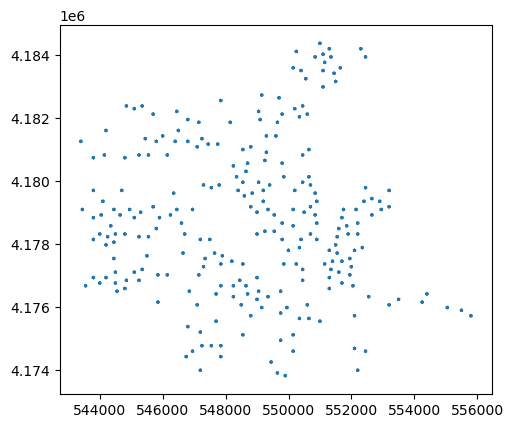

In [38]:
# Set the active geometry column to geometry_x
df6_geo = df6_geo.set_geometry('geometry_x')


df6_geo.plot()


In [39]:

# Then save to GeoJSON
df6_geo.to_file('../data/Results/SF_final_alljoin_hex_05_01_26.geojson', driver='GeoJSON')

AttributeError: 'float' object has no attribute 'encode'

In [ ]:


# Then save to GeoJSON
df6_geo.to_file('../data/Results/SF_final_alljoin_hex_5_01_26.shp')

/tmp/ipykernel_398696/2242474030.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  df6_geo.to_file('../data/Results/SF_final_alljoin_hex_5_01_26.shp')
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'median_ndvi' to 'median_ndv'
  ogr_write(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'majority_ndvi' to 'majority_n'
  ogr_write(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'min_highway' to 'min_highwa'
  ogr_write(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'max_highway' to 'max_highwa'
  ogr_write(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/pyogrio/raw.py:7

AttributeError: 'float' object has no attribute 'encode'

# Habitat

In [ ]:
#combine both the raster/polygon datasets and add in inext values 
#combine d4 dataframe last where we left off based on labels 
#now finally we inext result and use area to divide it 
inext_data_all = pd.read_csv("./data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv")


In [ ]:


# Load all the different dataframes with proper names

inext_data_human = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_human_reshape_2026_04_26.csv")
inext_data_water = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_water_reshape_2026_04_26.csv")
inext_data_tree = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_trees_reshape_2026_04_26.csv")
inext_data_shrubgrass = pd.read_csv("../data/Results/SF_100hex_asymp_ebird_shrubgrass_reshape_2026_04_26.csv")
#inext_data_native = pd.read_csv("/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/inext_results/results_10.7.25/asy_est/SF_exotic_results.10.19.25_NA_AsyEst.csv")
#inext_data_nonnative = pd.read_csv("/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/inext_results/results_10.7.25/asy_est/SF_exotic_results.10.19.25_AsyEst.csv")
#print(inext_data_nonnative) = pd.read_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/inext_results/results_10.7.25/asy_est/SF_exotic_results.10.19.25__AsyEst.csv')

inext_data_native = pd.read_csv('../data/Results/SF_100hex_asymp_ebird_native_reshape_2026_04_26.csv')
inext_data_nonnative = pd.read_csv('../data/Results/SF_100hex_asymp_ebird_nonnative_reshape_2026_04_26.csv')

#/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/inext_results/results_10.7.25/asy_est/SF_exotic_results.10.19.25_ebird_native_reshape_AsyEst.csv
#/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/inext_results/results_10.7.25/asy_est/SF_inexthab_results_hex.10.19.25_ebird_human_reshape_AsyEst.csv


In [ ]:

# Check column names in each dataframe
print("Column names in each dataframe:")
for df_name, df in {
    'all': inext_data_all,
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native' : inext_data_native,
    'nonnative' : inext_data_nonnative
}.items():
    print(f"{df_name}: {df.columns.tolist()}")

# Standardize column names across all dataframes
for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'Assemblage' in df.columns:
        df.rename(columns={'Assemblage': 'label'}, inplace=True)
    
    # Clean IDs for consistency
    if 'label' in df.columns:
        df['label'] = df['label'].str.strip().str.upper()

# Create the base dataframe with unique combinations of label and Diversity
# First, collect all unique labels and diversity metrics
all_labels = set()
all_diversity = set()

for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'label' in df.columns:
        all_labels.update(df['label'].unique())
    if 'Diversity' in df.columns:
        all_diversity.update(df['Diversity'].unique())

# Convert sets to lists for DataFrame creation
all_labels = list(all_labels)
all_diversity = list(all_diversity)

# Create all combinations
import itertools
combinations = list(itertools.product(all_labels, all_diversity))
base_df = pd.DataFrame(combinations, columns=['label', 'Diversity'])

# Function to add each habitat's estimates
def add_habitat_estimates(base_df, habitat_df, habitat_name):
    """
    Adds estimate columns from a habitat dataset to the base dataframe
    """
    # Make a copy of the input dataframe
    df = habitat_df.copy()
    
    # Ensure we have the correct column names
    if 'Estimator' in df.columns:
        # Create a new dataframe with the columns we need
        temp_df = df[['label', 'Diversity', 'Estimator']].copy()
        # Rename the estimate column
        temp_df = temp_df.rename(columns={'Estimator': f'{habitat_name}_estimate'})
        
        # Merge with the base dataframe
        merged_df = base_df.merge(temp_df, on=['label', 'Diversity'], how='left')
        return merged_df
    else:
        print(f"Warning: 'Estimator' column not found in {habitat_name} dataframe. Columns: {df.columns.tolist()}")
        return base_df

# Start with the base dataframe
result_df = base_df.copy()

# Add estimates from each habitat type
habitat_types = {
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native': inext_data_native,
    'nonnative': inext_data_nonnative,
    'all': inext_data_all,
    
}

for habitat_name, habitat_df in habitat_types.items():
    print(f"Processing {habitat_name} habitat data...")
    result_df = add_habitat_estimates(result_df, habitat_df, habitat_name)

# Add additional columns from holc_prj 
# (First, make sure 'label' in holc_prj is standardized)
if 'label' in holc_prj.columns:
    holc_prj['label'] = holc_prj['label'].str.strip().str.upper()
    
    # Add all columns except 'label' (which is already in result_df)
    other_columns = [col for col in holc_prj.columns if col != 'label']
    if other_columns:  # Only merge if there are columns to add
        result_df = result_df.merge(holc_prj[['label'] + other_columns], on='label', how='left')

# Display the results
print("\nFinal dataframe shape:", result_df.shape)
print("Columns in final dataframe:", result_df.columns.tolist())
print("\nSample rows from final dataframe:")
print(result_df.head())

# Check for missing values
print("\nMissing value counts by column:")
print(result_df.isna().sum())




Column names in each dataframe:
all: ['Unnamed: 0', 'Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
human: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
water: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
tree: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
shrubgrass: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
native: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
nonnative: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
Processing human habitat data...
Processing water habitat data...
Processing tree habitat data...
Processing shrubgrass habitat data...
Processing native habitat data...
Processing nonnative habitat data...
Processing all habitat data...

Final dataframe shape: (759, 20)
Columns in final dataframe: ['label', 'Diversity', 'human_estimate', 'water_estimate', 'tree_estimate

In [ ]:

# Check column names in each dataframe
print("Column names in each dataframe:")
for df_name, df in {
    'all': inext_data_all,
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native' : inext_data_native,
    'nonnative' : inext_data_nonnative
}.items():
    print(f"{df_name}: {df.columns.tolist()}")

# Standardize column names across all dataframes
for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'Assemblage' in df.columns:
        df.rename(columns={'Assemblage': 'label'}, inplace=True)
    
    # Clean IDs for consistency
    if 'label' in df.columns:
        df['label'] = df['label'].str.strip().str.upper()

# Create the base dataframe with unique combinations of label and Diversity
# First, collect all unique labels and diversity metrics
all_labels = set()
all_diversity = set()

for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'label' in df.columns:
        all_labels.update(df['label'].unique())
    if 'Diversity' in df.columns:
        all_diversity.update(df['Diversity'].unique())

# Convert sets to lists for DataFrame creation
all_labels = list(all_labels)
all_diversity = list(all_diversity)

# Create all combinations
import itertools
combinations = list(itertools.product(all_labels, all_diversity))
base_df = pd.DataFrame(combinations, columns=['label', 'Diversity'])

# Function to add each habitat's estimates
def add_habitat_estimates(base_df, habitat_df, habitat_name):
    """
    Adds estimate columns from a habitat dataset to the base dataframe
    """
    # Make a copy of the input dataframe
    df = habitat_df.copy()
    
    # Ensure we have the correct column names
    if 'Estimator' in df.columns:
        # Create a new dataframe with the columns we need
        temp_df = df[['label', 'Diversity', 'Estimator']].copy()
        # Rename the estimate column
        temp_df = temp_df.rename(columns={'Estimator': f'{habitat_name}_estimate'})
        
        # Merge with the base dataframe
        merged_df = base_df.merge(temp_df, on=['label', 'Diversity'], how='left')
        return merged_df
    else:
        print(f"Warning: 'Estimator' column not found in {habitat_name} dataframe. Columns: {df.columns.tolist()}")
        return base_df

# Start with the base dataframe
result_df = base_df.copy()

# Add estimates from each habitat type
habitat_types = {
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native': inext_data_native,
    'nonnative': inext_data_nonnative,
    'all': inext_data_all
}

for habitat_name, habitat_df in habitat_types.items():
    print(f"Processing {habitat_name} habitat data...")
    result_df = add_habitat_estimates(result_df, habitat_df, habitat_name)

# Add additional columns from holc_prj 
# (First, make sure 'label' in holc_prj is standardized)
if 'label' in holc_prj.columns:
    holc_prj['label'] = holc_prj['label'].str.strip().str.upper()
    
    # Add all columns except 'label' (which is already in result_df)
    other_columns = [col for col in holc_prj.columns if col != 'label']
    if other_columns:  # Only merge if there are columns to add
        result_df = result_df.merge(holc_prj[['label'] + other_columns], on='label', how='left')

# Display the results
print("\nFinal dataframe shape:", result_df.shape)
print("Columns in final dataframe:", result_df.columns.tolist())
print("\nSample rows from final dataframe:")
print(result_df.head())

# Check for missing values
print("\nMissing value counts by column:")
print(result_df.isna().sum())




Column names in each dataframe:
all: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
human: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
water: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
tree: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
shrubgrass: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
native: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
nonnative: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
Processing human habitat data...
Processing water habitat data...
Processing tree habitat data...
Processing shrubgrass habitat data...
Processing native habitat data...
Processing nonnative habitat data...
Processing all habitat data...

Final dataframe shape: (1803, 20)
Columns in final dataframe: ['label', 'Diversity', 

In [ ]:
#Now let's join everything by label id 


#result_df from inext estimates
#raster_df
#polygon_df 
final = df6.merge(result_df, left_on = 'hex_id', right_on= 'label', how='left' )
#final = df6.merge(df5, on = 'label', how='left' )
 
final


,hex_id,grade_x,geometry_x,min_ndvi,max_ndvi,mean_ndvi,count_ndvi,std_ndvi,median_ndvi,majority_ndvi,...,city,state,city_survey,category,grade,residential,commercial,industrial,fill,geometry
0,3395_C,C,"POLYGON ((550845.991 4183886.263, 550795.991 4...",0.154538,0.692172,0.348543,1028,0.119977,0.308455,0.154538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,3395_C,C,"POLYGON ((550845.991 4183886.263, 550795.991 4...",0.154538,0.692172,0.348543,1028,0.119977,0.308455,0.154538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,3395_C,C,"POLYGON ((550845.991 4183886.263, 550795.991 4...",0.154538,0.692172,0.348543,1028,0.119977,0.308455,0.154538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,3395_C,C,"POLYGON ((550845.991 4183886.263, 550795.991 4...",0.154538,0.692172,0.348543,1028,0.119977,0.308455,0.154538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,3395_C,C,"POLYGON ((550845.991 4183886.263, 550795.991 4...",0.154538,0.692172,0.348543,1028,0.119977,0.308455,0.154538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2272,3481_D,D,"POLYGON ((551295.991 4176871.457, 551245.991 4...",0.262354,0.734100,0.450693,1029,0.100710,0.428283,0.396042,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2273,3481_D,D,"POLYGON ((551295.991 4176871.457, 551245.991 4...",0.262354,0.734100,0.450693,1029,0.100710,0.428283,0.396042,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2274,3481_D,D,"POLYGON ((551295.991 4176871.457, 551245.991 4...",0.262354,0.734100,0.450693,1029,0.100710,0.428283,0.396042,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2275,3481_D,D,"POLYGON ((551295.991 4176871.457, 551245.991 4...",0.262354,0.734100,0.450693,1029,0.100710,0.428283,0.396042,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [ ]:
final.to_csv('../data/Results/SF_final_alljoin__hex_4.26.26.csv', index=False)

Now we move onto Random Forest modelling